# Estimate a discrete generic equivalent layer

### Things we have to import

In [1]:
import numpy as np

In [2]:
import matplotlib.pyplot as plt

In [3]:
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable

In [4]:
from scipy.fft import fftfreq, fftshift

In [5]:
import time

In [6]:
import pickle

In [7]:
from gravmag import data_structures, utils, aux_vedo, transforms, inverse_distance, convolve, filters, constants, eqlayer
from gravmag.models import rectangular_prism as rp

In [8]:
import vedo

In [9]:
# set the backend for vedo
vedo.settings.default_backend= 'vtk'
#vedo.settings.default_backend= '2d'

### Load data

In [10]:
boundary_points = pickle.load(open('model/1_model_boundary_points.pickle', 'rb'))

In [11]:
# append the first point at the end to plot a closed curve
boundary_points = np.vstack([boundary_points, boundary_points[0]])

In [12]:
model = pickle.load(open('model/1_model.pickle', 'rb'))

In [13]:
model_area = pickle.load(open('model/1_model_area.pickle', 'rb'))
model_shape = pickle.load(open('model/1_model_shape.pickle', 'rb'))

In [14]:
mag_intensity = pickle.load(open('model/1_model_mag_intensity.pickle', 'rb'))
mag_inc = pickle.load(open('model/1_model_mag_inc.pickle', 'rb'))
mag_dec = pickle.load(open('model/1_model_mag_dec.pickle', 'rb'))

In [15]:
main_field = pickle.load(open('model/2_main_field.pickle', 'rb'))

In [16]:
print('Main field inc = {}° dec = {}°'.format(main_field['inc'], main_field['dec']))

Main field inc = -30° dec = 10°


In [17]:
simulated_fields = pickle.load(open('model/2_simulated_fields.pickle', 'rb'))

In [18]:
coordinates_grid = pickle.load(open('model/2_coordinates_grid.pickle', 'rb'))

In [19]:
print('Regular grid of coordinates on the horizontal plane {} m'.format(coordinates_grid['z']))

Regular grid of coordinates on the horizontal plane -150 m


### Get preliminary information from loaded data

In [20]:
# Cartesian components of the model magnetization
v_hat = utils.unit_vector(inc=mag_inc[0], dec=mag_dec[0])

In [21]:
# compute a normalized horizontal projection of v_hat to plot
v_hat_horizontal = v_hat[:2]/np.linalg.norm(v_hat[:2])

In [22]:
print('Synthetic source magnetization inc = {}° dec = {}°'.format(mag_inc[0], mag_dec[0]))

Synthetic source magnetization inc = -10.2° dec = -19.8°


In [23]:
# Grid spacing
dx, dy = data_structures.grid_xy_spacing(coordinates_grid['area'], coordinates_grid['shape'])

In [24]:
X, Y = data_structures.grid_xy_to_full_matrices_view(
    x = coordinates_grid['x'],
    y = coordinates_grid['y'],
    shape = coordinates_grid['shape']
)

In [25]:
# Cartesian components of the main field
F_hat = utils.unit_vector(inc=main_field['inc'], dec=main_field['dec'])

In [26]:
# Cartesian components of the dipoles forming the equivalent layers
h_inc=90
h_dec=0
h_hat = utils.unit_vector(inc=h_inc, dec=h_dec)

In [27]:
print('Layer magnetization inc = {}° dec = {}°'.format(h_inc, h_dec))

Layer magnetization inc = 90° dec = 0°


In [28]:
# compute a normalized horizontal projection of F_hat and h_hat to plot
F_hat_horizontal = F_hat[:2]/np.linalg.norm(F_hat[:2])
h_hat_horizontal = h_hat[:2]/np.linalg.norm(h_hat[:2])

### Estimate the discrete Neumann's equivalent layer

In [29]:
# set a layer that crosses the sources
z_layer = 200

In [30]:
print('The distance from coordinates grid to layer is {} m'.format(z_layer-coordinates_grid['z']))

The distance from coordinates grid to layer is 350 m


In [31]:
# compute the SEDM
R2 = inverse_distance.sedm_BTTB(
    data_grid = coordinates_grid, 
    delta_z = z_layer - coordinates_grid['z'],
    ordering = 'xy'
)

In [32]:
# compute the tensor components (second derivatives) of the inverse distance function
Tensor = inverse_distance.grad_tensor_BTTB(
    data_grid = coordinates_grid,
    delta_z = z_layer - coordinates_grid['z'],
    SEDM = R2,
    ordering = 'xy',
    components=['xx', 'xy', 'xz', 'yy', 'yz', 'zz']
)

In [33]:
# compute the eigenvalues matrices associated to second derivatives of inverse distance function
L_Tensor = dict()
for component in ['xx', 'xy', 'xz', 'yy', 'yz', 'zz']:
    L_Tensor[component] = convolve.eigenvalues_BCCB(BTTB_metadata=Tensor[component])

In [34]:
# directional factor to compute the approximated total-field anomaly
a = utils.directional_factors(t=h_hat, u=F_hat)

In [35]:
# Compute the resultant eigenvalues matrix associated with the directional derivative of second order
L = np.empty_like(L_Tensor['xx'])
for component in ['xx', 'xy', 'xz', 'yy', 'yz']:
    L += a[component]*L_Tensor[component]

In [36]:
# estimate the pseudogravity anomaly on the layer plane
dipole_convergence, dipole_layer = eqlayer.method_iterative_deconvolution_TOB20(
    eigenvalues_matrices=[L],
    data_vectors=[simulated_fields['atfa']],
    epsilon=1e-7,
    ITMAX=100
)

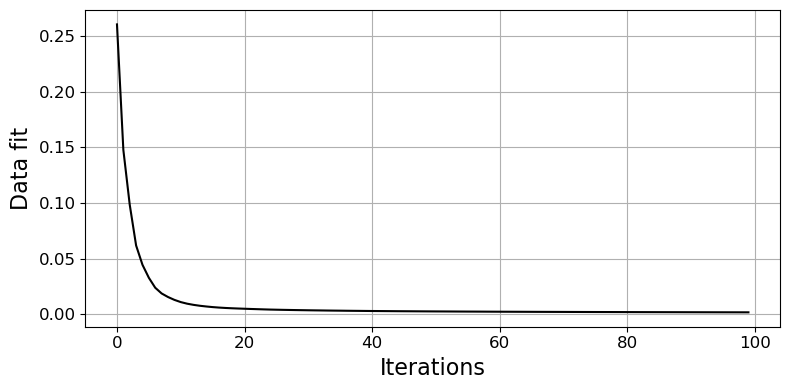

In [37]:
fig, ax = plt.subplots(figsize=(8,4))

iterations = [i for i in range(len(dipole_convergence))]
ax.plot(
    iterations, dipole_convergence, linestyle='-', c='k', alpha=1, markersize=4
)
ax.tick_params(axis='x', labelsize=12)
ax.tick_params(axis='y', labelsize=12)
ax.set_xlabel('Iterations', fontsize=16)
ax.set_ylabel('Data fit', fontsize=16)
ax.grid(True)
plt.tight_layout()
plt.show()

### Compute the data fit

In [38]:
# list for storing the predicted magnetic field components
predicted_fields = dict()

In [39]:
# magnetic induction field component x
result = np.zeros_like(simulated_fields['bx'])

for h_component, component in zip(h_hat, ['xx', 'xy', 'xz']):
    result[:] += h_component*convolve.product_BCCB_vector(
        eigenvalues = L_Tensor[component],
        ordering = 'row',
        v = dipole_layer
    )

predicted_fields['bx'] = result # convert to nT

# magnetic induction field component y
result = np.zeros_like(simulated_fields['by'])

for h_component, component in zip(h_hat, ['xy', 'yy', 'yz']):
    result[:] += h_component*convolve.product_BCCB_vector(
        eigenvalues = L_Tensor[component],
        ordering = 'row',
        v = dipole_layer
    )

predicted_fields['by'] = result # convert to nT

# magnetic induction field component z
result = np.zeros_like(simulated_fields['bz'])

for h_component, component in zip(h_hat, ['xz', 'yz', 'zz']):
    result[:] += h_component*convolve.product_BCCB_vector(
        eigenvalues = L_Tensor[component],
        ordering = 'row',
        v = dipole_layer
    )

predicted_fields['bz'] = result # convert to nT

In [40]:
# amplitude of anomalous B field
predicted_fields['b'] = np.sqrt(
    predicted_fields['bx']**2 + 
    predicted_fields['by']**2 + 
    predicted_fields['bz']**2
)

In [41]:
# reduction to the pole
result = np.zeros_like(simulated_fields['bx'])

result = convolve.product_BCCB_vector(
    eigenvalues = L_Tensor['zz'],
    ordering = 'row',
    v = dipole_layer
)

FT_result = transforms.DFT(
    data=data_structures.grid_xy_full_flatten_to_matrix(
        data=result,
        ordering='xy',
        shape=coordinates_grid['shape']
    ), 
    pad_mode='linear_ramp'
)

wavenumbers = data_structures.grid_wavenumbers(
    grid=coordinates_grid,
    pad=True
)

Av = filters.direction(
    wavenumbers=wavenumbers,
    inc=mag_inc[0],
    dec=mag_dec[0]
)
Av[0,0]=1.

FT_result *= wavenumbers['z'] / Av

result = transforms.IDFT(FT_data=FT_result, unpad=True)

predicted_fields['rtp'] = data_structures.grid_xy_full_matrix_to_flatten(
    grid=result,
    ordering='xy'
)

In [42]:
# approximated total-field anomaly
result = np.zeros_like(simulated_fields['bx'])

for component in ['xx', 'xy', 'xz', 'yy', 'yz']:
    result[:] += convolve.product_BCCB_vector(
        eigenvalues = a[component]*L_Tensor[component],
        ordering = 'row',
        v = dipole_layer
    )

predicted_fields['atfa'] = result # convert to nT

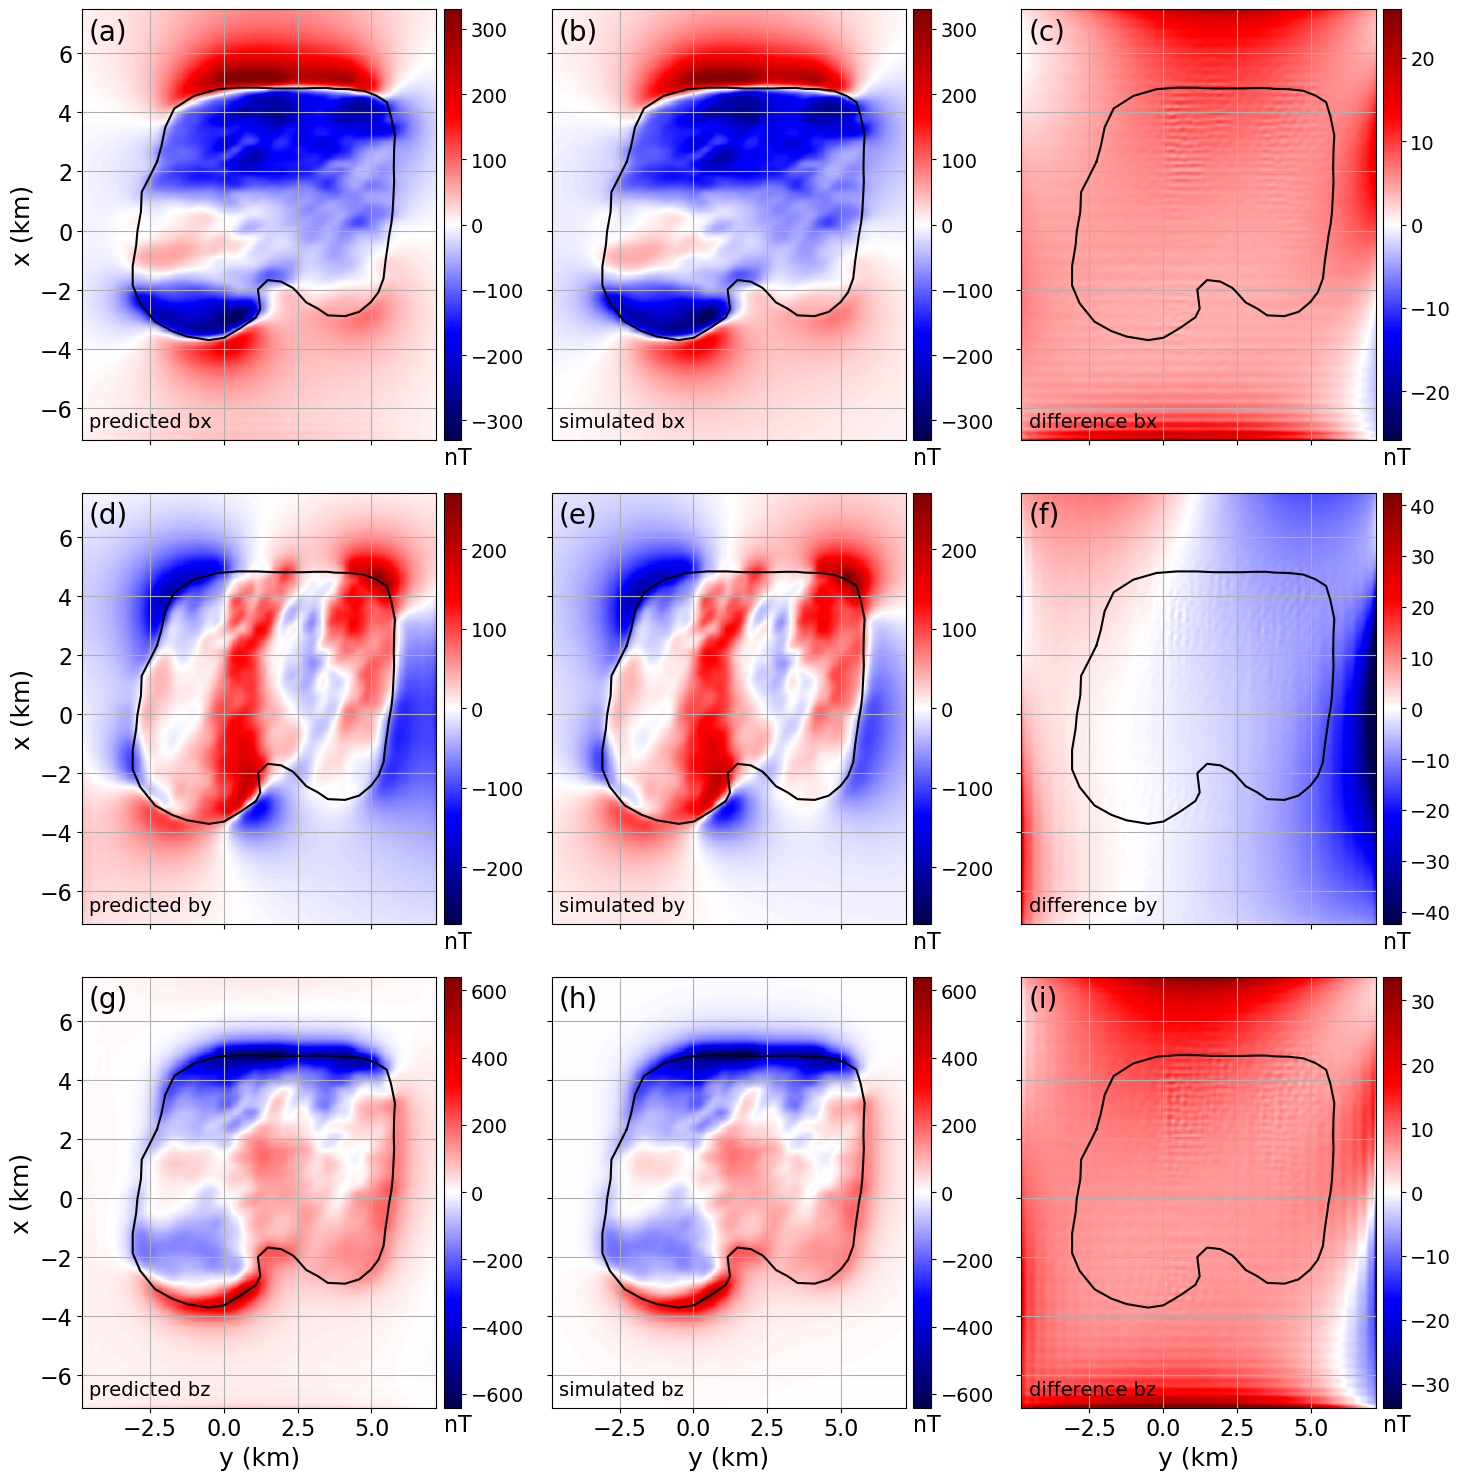

In [43]:
# plot figure
fig = plt.figure(
    layout= 'tight', 
    figsize=(15,15)
)
mosaic = fig.subplot_mosaic(
    mosaic = '''
             abc
             def
             ghi
             ''',
    sharex=True, sharey=True
)

labels = [['(a)', '(b)', '(c)'], ['(d)', '(e)', '(f)'], ['(g)', '(h)', '(i)']]

mosaic_elements = [['a', 'b', 'c'], ['d', 'e', 'f'], ['g', 'h', 'i']]

for (mosaic_row, field, labels_row) in zip(
    mosaic_elements, 
    ['bx', 'by', 'bz'],
    labels
):
    data_list = [
        predicted_fields[field], 
        simulated_fields[field],
        predicted_fields[field] - simulated_fields[field]
    ]
    bounds_list = 2*[np.max(np.abs(simulated_fields[field]))] + [0.6*np.max(np.abs(data_list[2]))]
    titles = ['predicted '+field, 'simulated '+field, 'difference '+field]
    
    for mosaic_element, data, bound, label, title in zip(mosaic_row, data_list, bounds_list, labels_row, titles):
    
        ax = mosaic[mosaic_element]
        ax.axis('scaled')
        im = ax.pcolormesh(
            Y*0.001, X*0.001, 
            data_structures.grid_xy_full_flatten_to_matrix(
                data=data,
                ordering='xy',
                shape=coordinates_grid['shape']
            ),
            cmap='seismic', vmin=-bound, vmax=bound
        )
        ax_divider = make_axes_locatable(ax)
        cax = ax_divider.append_axes("right", size="5%", pad="2%")
        cb = fig.colorbar(im, cax=cax)
        cb.ax.tick_params(labelsize=14)
        cb.ax.set_xlabel('nT', fontsize=16, loc='left')
        ax.plot(boundary_points[:,1]*0.001, boundary_points[:,0]*0.001, 'k-')
        ax.set_ylim(0.001*coordinates_grid['area'][0], 0.001*coordinates_grid['area'][1])
        ax.set_xlim(0.001*coordinates_grid['area'][2], 0.001*coordinates_grid['area'][3])
        ax.tick_params(axis='x', labelsize=16)
        ax.tick_params(axis='y', labelsize=16)
        ax.grid()
        ax.annotate(label, xy=(0.02, 0.93), xycoords='axes fraction', fontsize=20)
        ax.annotate(title, xy=(0.02, 0.03), xycoords='axes fraction', fontsize=14)
        # ax.arrow(x=6, y=5.2, dx=F_hat_horizontal[1], dy=F_hat_horizontal[0], 
        #          width=0.2, length_includes_head=False, head_width=0.6, linewidth=2, color='purple') 
        # ax.arrow(x=6, y=5.2, dx=h_hat_horizontal[1], dy=h_hat_horizontal[0], 
        #          width=0.2, length_includes_head=False, head_width=0.6, linewidth=1.5, color='black')

# set vertical and horizontal spaces between subplots
#fig.subplots_adjust(wspace=0.20, hspace=0.30)
    
for element in ['a','d','g']:
    mosaic[element].set_ylabel('x (km)', fontsize=18)
for element in ['g','h', 'i']:
    mosaic[element].set_xlabel('y (km)', fontsize=18)

#plt.savefig('3_dipole_bx_by_bz.png', dpi=300)

plt.show()

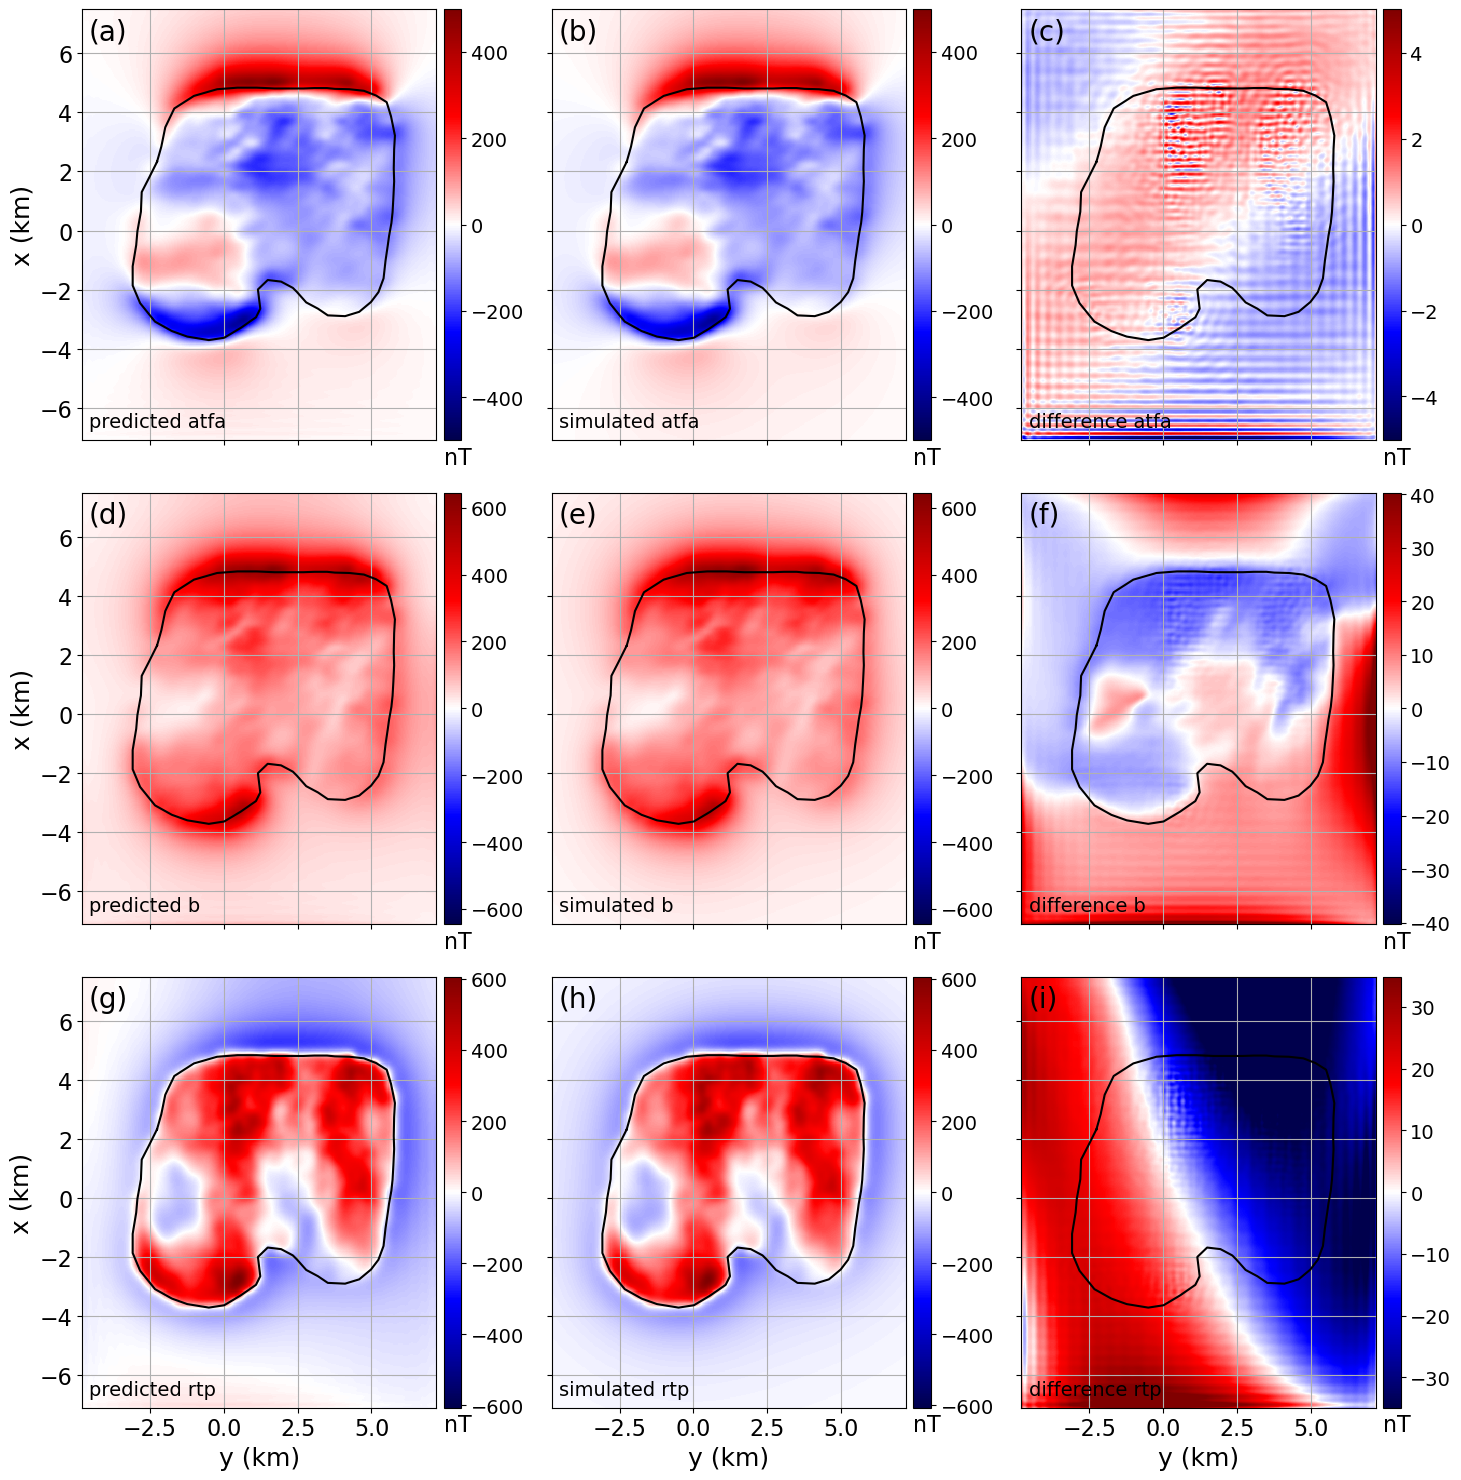

In [44]:
# plot figure
fig = plt.figure(
    layout= 'tight', 
    figsize=(15,15)
)
mosaic = fig.subplot_mosaic(
    mosaic = '''
             abc
             def
             ghi
             ''',
    sharex=True, sharey=True
)

labels = [['(a)', '(b)', '(c)'], ['(d)', '(e)', '(f)'], ['(g)', '(h)', '(i)']]

mosaic_elements = [['a', 'b', 'c'], ['d', 'e', 'f'], ['g', 'h', 'i']]

for (mosaic_row, field, labels_row) in zip(
    mosaic_elements, 
    ['atfa', 'b', 'rtp'],
    labels
):
    data_list = [
        predicted_fields[field], 
        simulated_fields[field],
        predicted_fields[field] - simulated_fields[field]
    ]
    bounds_list = 2*[np.max(np.abs(simulated_fields[field]))] + [0.6*np.max(np.abs(data_list[2]))]
    titles = ['predicted '+field, 'simulated '+field, 'difference '+field]
    
    for mosaic_element, data, bound, label, title in zip(mosaic_row, data_list, bounds_list, labels_row, titles):
    
        ax = mosaic[mosaic_element]
        ax.axis('scaled')
        im = ax.pcolormesh(
            Y*0.001, X*0.001, 
            data_structures.grid_xy_full_flatten_to_matrix(
                data=data,
                ordering='xy',
                shape=coordinates_grid['shape']
            ),
            cmap='seismic', vmin=-bound, vmax=bound
        )
        ax_divider = make_axes_locatable(ax)
        cax = ax_divider.append_axes("right", size="5%", pad="2%")
        cb = fig.colorbar(im, cax=cax)
        cb.ax.tick_params(labelsize=14)
        cb.ax.set_xlabel('nT', fontsize=16, loc='left')
        ax.plot(boundary_points[:,1]*0.001, boundary_points[:,0]*0.001, 'k-')
        ax.set_ylim(0.001*coordinates_grid['area'][0], 0.001*coordinates_grid['area'][1])
        ax.set_xlim(0.001*coordinates_grid['area'][2], 0.001*coordinates_grid['area'][3])
        ax.tick_params(axis='x', labelsize=16)
        ax.tick_params(axis='y', labelsize=16)
        ax.grid()
        ax.annotate(label, xy=(0.02, 0.93), xycoords='axes fraction', fontsize=20)
        ax.annotate(title, xy=(0.02, 0.03), xycoords='axes fraction', fontsize=14)
        # ax.arrow(x=6, y=5.2, dx=F_hat_horizontal[1], dy=F_hat_horizontal[0], 
        #          width=0.2, length_includes_head=False, head_width=0.6, linewidth=2, color='purple') 
        # ax.arrow(x=6, y=5.2, dx=h_hat_horizontal[1], dy=h_hat_horizontal[0], 
        #          width=0.2, length_includes_head=False, head_width=0.6, linewidth=1.5, color='black')

# set vertical and horizontal spaces between subplots
#fig.subplots_adjust(wspace=0.20, hspace=0.30)
    
for element in ['a','d','g']:
    mosaic[element].set_ylabel('x (km)', fontsize=18)
for element in ['g','h', 'i']:
    mosaic[element].set_xlabel('y (km)', fontsize=18)  

#plt.savefig('3_dipole_atfa_b_rtp.png', dpi=300)
    
plt.show()

### Save the estimated Neumann's layer and its predicted potential fields

In [45]:
pickle.dump(dipole_layer, open('model/4_generic_dipole_layer.pickle', 'wb'))

In [46]:
pickle.dump(predicted_fields, open('model/4_generic_dipole_predicted_fields.pickle', 'wb'))